# Hackathon – Dataset C (COVID vaccine) · Notebook 04 of 09
## Pre-processing – cleaning, feature engineering, comparing four options

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


## 4. Pre-processing
### 4.1 Cleaning + feature engineering (row-wise, so it cannot leak information between folds)
All steps below only look at one row at a time, so they can safely run *before* the train/validation split. Everything that **learns**
from data (imputation values, scaling, rare-category grouping) lives inside a scikit-learn `Pipeline` and is therefore re-fitted inside every
cross-validation fold – no data leakage.

The cleaning function (defined once in `hackathon_utils.py` and used by every model):

In [2]:
show_source(clean_features)

```python
def clean_features(df):
    """Row-wise cleaning and feature engineering (learns nothing from data, so it cannot leak)."""
    d = df[FEATURES].copy()
    zero_coded = d[OPINION[:2]].eq(0)                                  # 0 is not a valid answer on a 1-5 scale
    d['n_missing'] = d.isna().sum(axis=1) + zero_coded.sum(axis=1)     # engagement proxy
    d[OPINION[:2]] = d[OPINION[:2]].mask(zero_coded)                   # disguised missing -> NaN
    d[CATEGORICAL] = d[CATEGORICAL].astype(object)
    not_employed = d['employment_status'].isin(['Not in Labor Force', 'Unemployed'])
    d.loc[not_employed & d['employment_sector'].isna(), 'employment_sector'] = 'not_employed'   # structural missing
    d['census_msa'] = d['census_msa'].str.replace(r'\s+', ' ', regex=True)
    d['number_chronic_med_conditions'] = d['number_chronic_med_conditions'].clip(upper=3)    # top-code (binning)
    d['behaviour_score'] = d[BEHAVIOURAL].sum(axis=1, min_count=1)                          # 0-7 protective behaviours
    d['vacc_attitude'] = (d['opinion_covid_vacc_effective'] + d['opinion_covid_risk']
                          - d['opinion_covid_sick_from_vacc'])
    d['dont_know_any'] = d[OPINION].eq(3).any(axis=1).astype(int)
    d['age_ord'] = d['age_group'].map({a: i for i, a in enumerate(AGE_ORDER)})
    d['education_ord'] = d['education'].map({a: i for i, a in enumerate(EDU_ORDER)})
    d['income_ord'] = d['income_poverty'].map({a: i for i, a in enumerate(INC_ORDER)})
    return d

```

In [3]:
clean_features(X_all).head()

,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,child_under_6_months,health_worker,health_insurance,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,n_missing,behaviour_score,vacc_attitude,dont_know_any,age_ord,education_ord,income_ord
0,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,NaN,45 - 54 Years,12 Years,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Principle City",3.0,2.0,0,4.0,4.0,2.0,construction,1,1,4.0,6.0,0,2,1.0,1.0
1,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,45 - 54 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,0,5.0,2.0,1.0,education,0,0,3.0,6.0,0,2,3.0,1.0
2,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Not Married,Own,Employed,"MSA, Not Principle City",0.0,0.0,0,2.0,2.0,5.0,wholesale,3,1,0.0,-1.0,0,2,2.0,1.0
3,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,NaN,65+ Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,1,3.0,3.0,2.0,not_employed,1,2,3.0,4.0,1,4,3.0,1.0
4,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,18 - 34 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,"MSA, Not Principle City",0.0,0.0,0,3.0,2.0,2.0,wholesale,0,0,1.0,3.0,1,0,3.0,1.0


### 4.2 Four pre-processing options
| Option | Imputation | Encoding | Extra |
|---|---|---|---|
| **P1 basic** | median (numeric) / most-frequent (categorical) | one-hot all categoricals | – |
| **P2 missing-aware** | median + **missing-indicator** columns; categorical NaN → **"Missing"** level | one-hot | – |
| **P3 ordinal + FE** | as P2 | **ordinal codes** for age / education / income, one-hot (rare levels < 30 grouped) for nominal | engineered features |
| **P4 binned opinions** | as P3 | as P3, but opinion scales **binned** into lower (1–2) / don't know (3) / upper (4–5) and one-hot encoded | engineered features |

Numeric columns are standardised (needed for regularised logistic regression; harmless for trees).

Implementation (from `hackathon_utils.py`):

In [4]:
show_source(make_preprocessor)

```python
def make_preprocessor(option):
    """Return one of the four pre-processing options as a ColumnTransformer."""
    if option == 'P1_basic':
        parts = [('num', num_pipe(False), NUM_BASE), ('cat', cat_pipe('mode'), CATEGORICAL)]
    elif option == 'P2_missing_aware':
        parts = [('num', num_pipe(True), NUM_BASE), ('cat', cat_pipe('missing'), CATEGORICAL)]
    elif option == 'P3_ordinal_fe':
        parts = [('num', num_pipe(True), NUM_BASE + ENGINEERED), ('cat', cat_pipe('missing', 30), NOMINAL)]
    elif option == 'P4_binned':
        non_opinion = [c for c in NUM_BASE if c not in OPINION]
        parts = [('num', num_pipe(True), non_opinion + ENGINEERED),
                 ('op', Pipeline([('bin', FunctionTransformer(bin_opinions, feature_names_out='one-to-one')),
                                  ('imp', SimpleImputer(strategy='constant', fill_value='Missing')),
                                  ('oh', ohe())]), OPINION),
                 ('cat', cat_pipe('missing', 30), NOMINAL)]
    else:
        raise ValueError(option)
    return ColumnTransformer(parts, remainder='drop')

```

In [5]:
from sklearn.linear_model import LogisticRegression
for opt in PREP_OPTIONS:
    n = make_pipe(opt, LogisticRegression()).fit(X_all.head(800), y_all.head(800))[:-1].transform(X_all.head(5)).shape[1]
    print(f'{opt:18s} -> {n} model inputs')

P1_basic           -> 68 model inputs
P2_missing_aware   -> 90 model inputs
P3_ordinal_fe      -> 70 model inputs
P4_binned          -> 75 model inputs


### 4.3 Hold-out split and the evaluation helpers
We keep **20 % of the labelled data as an untouched hold-out set** (never used for tuning or model choice) and do all comparison and tuning on the
remaining 80 % ("development set") with **repeated stratified 5-fold cross-validation** (5 folds × 2 repeats = 10 estimates per model),
which also gives us the size of the random variation (standard deviation across folds).

In [6]:
print('development:', X_dev.shape, f'(accept rate {y_dev.mean():.3f})  | hold-out:', X_hold.shape,
      f'(accept rate {y_hold.mean():.3f})')
print(f'Repeated CV: {CV_SPLITS} folds x {CV_REPEATS} repeats; decision strategies: {STRATEGIES}')
show_source(evaluate_probs)

development: (3804, 29) (accept rate 0.327)  | hold-out: (952, 29) (accept rate 0.327)
Repeated CV: 5 folds x 2 repeats; decision strategies: ['thr 0.5', 'single thr', 'personal thr']


```python
def evaluate_probs(y, prob, X, scenario=MAIN):
    """Probability metrics + task metric ($ per resident) for each decision strategy."""
    y = np.asarray(y)
    nobody = scenario.cost(y, np.zeros_like(y), X)
    oracle = scenario.cost(y, y, X)
    out = {'ROC-AUC': roc_auc_score(y, prob), 'log-loss': log_loss(y, prob), 'Brier': brier_score_loss(y, prob),
           'F1@0.5': f1_score(y, np.asarray(prob) >= 0.5), 'accuracy@0.5': accuracy_score(y, np.asarray(prob) >= 0.5)}
    for s in STRATEGIES:
        c = scenario.cost(y, decide(prob, X, s, scenario), X)
        out[f'$/resident [{s}]'] = c / len(y)
        out[f'% saving captured [{s}]'] = 100 * (nobody - c) / (nobody - oracle)
    return out

```

### 4.4 Which pre-processing works best? (logistic regression and LightGBM, default settings)

In [7]:
t0 = time.time()
base_models = {
    'LogReg': lambda: LogisticRegression(C=0.1, max_iter=5000),
    'LightGBM': lambda: LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=30,
                                       subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                                       random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1),
}
prep_folds = []
for mname, mk in base_models.items():
    for opt in PREP_OPTIONS:
        f, _ = cv_evaluate(make_pipe(opt, mk()), X_dev, y_dev, name=f'{mname} | {opt}')
        f['family'], f['prep'] = mname, opt
        prep_folds.append(f)
prep_folds = pd.concat(prep_folds, ignore_index=True)
print(f'done in {time.time() - t0:.0f}s')
summarise(prep_folds)

done in 66s


,ROC-AUC,log-loss,$/resident [thr 0.5],$/resident [single thr],$/resident [personal thr],% saving captured [personal thr]
model,,,,,,
LightGBM | P1_basic,0.8325 ± 0.0157,0.4653 ± 0.02,3202.9487 ± 70.7943,3175.3662 ± 71.1007,3100.8983 ± 83.1353,63.0309 ± 3.5246
LightGBM | P2_missing_aware,0.8606 ± 0.0103,0.428 ± 0.0159,3149.3829 ± 65.9189,3118.4536 ± 65.809,3052.21 ± 67.1089,67.5746 ± 2.5617
LightGBM | P3_ordinal_fe,0.8618 ± 0.0108,0.4267 ± 0.0159,3151.9198 ± 59.9869,3118.4834 ± 64.5713,3048.3761 ± 68.2322,67.9524 ± 2.3638
LightGBM | P4_binned,0.8594 ± 0.0119,0.4289 ± 0.0169,3141.1165 ± 59.9254,3123.193 ± 61.8003,3060.8321 ± 66.6388,66.7813 ± 2.8465
LogReg | P1_basic,0.8352 ± 0.0142,0.4582 ± 0.0162,3194.2989 ± 62.9858,3163.2367 ± 58.2003,3097.4248 ± 83.3626,63.3573 ± 3.5211
LogReg | P2_missing_aware,0.8611 ± 0.0107,0.4266 ± 0.0153,3143.4005 ± 59.9278,3109.7612 ± 58.4245,3055.503 ± 64.9713,67.283 ± 2.3685
LogReg | P3_ordinal_fe,0.8609 ± 0.0113,0.4268 ± 0.0164,3139.1286 ± 68.7603,3111.1589 ± 59.6712,3059.3934 ± 67.7639,66.9254 ± 2.465
LogReg | P4_binned,0.8592 ± 0.0117,0.4288 ± 0.0169,3143.6195 ± 62.5644,3117.4327 ± 64.3024,3053.155 ± 71.2656,67.5011 ± 2.798


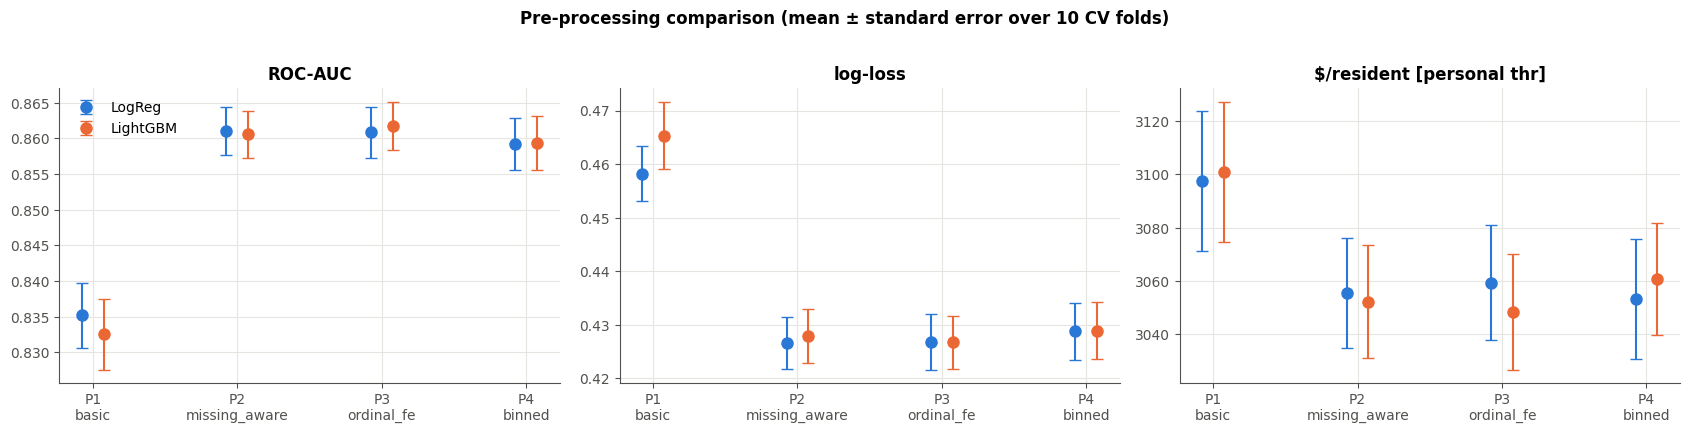

Best pre-processing per model family (lowest mean cost): {'LogReg': 'P4_binned', 'LightGBM': 'P3_ordinal_fe'}


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, metric in zip(axes, ['ROC-AUC', 'log-loss', '$/resident [personal thr]']):
    agg = prep_folds.groupby(['family', 'prep'])[metric].agg(['mean', 'std']).reset_index()
    x = np.arange(len(PREP_OPTIONS))
    for i, (fam, col) in enumerate(zip(base_models, [BLUE, ORANGE])):
        a = agg[agg['family'] == fam].set_index('prep').reindex(PREP_OPTIONS)
        ax.errorbar(x + (i - 0.5) * 0.15, a['mean'], yerr=a['std'] / np.sqrt(CV_SPLITS * CV_REPEATS),
                    fmt='o', color=col, capsize=4, ms=8, label=fam)
    ax.set_xticks(x, [p.replace('_', '\n', 1) for p in PREP_OPTIONS]); ax.set_title(metric)
axes[0].legend()
plt.suptitle('Pre-processing comparison (mean ± standard error over 10 CV folds)', fontweight='bold', y=1.02)
plt.tight_layout(); savefig('04_preprocessing'); plt.show()

prep_mean = prep_folds.groupby(['family', 'prep'])[['log-loss', '$/resident [personal thr]']].mean()
BEST_PREP = {fam: prep_mean.loc[fam]['$/resident [personal thr]'].idxmin() for fam in base_models}
print('Best pre-processing per model family (lowest mean cost):', BEST_PREP)

# ---- Save for the next notebooks ----
save_json(BEST_PREP, 'best_prep.json')
prep_folds.to_csv(ART_DIR / 'prep_comparison_folds.csv', index=False)

**Result.** The *missing-aware* options (P2–P4) beat plain imputation (P1) clearly and for both model families: ROC-AUC rises from
≈0.835 to ≈0.86, log-loss falls from ≈0.46 to ≈0.43 and the town saves roughly **\$40–50 per resident** (≈\$200 000 for the 4 749-person test town).
This confirms the EDA finding that *not answering a question* is itself informative. The differences **between** P2, P3 and P4 are smaller than the
fold-to-fold noise (standard error ≈ \$20), so we simply keep, for each family, the option with the lowest mean cost (printed above) and use it for all
later models of that family (the LightGBM choice is used for every one-hot-based tree model).

**Next:** notebook 05 tunes six model families using these pre-processing choices.